# CIE 2 — Activity 2: Simple House Price Prediction

**Institution:** Zeal Education Society's Zeal College of Engineering and Research, Narhe, Pune – 41  
**Department:** Artificial Intelligence & Data Science (AI & DS) | **Class:** T.Y. B.Tech (Semester V) | **Academic Year:** 2026–27  
**Course:** Machine Learning `[ADPC509]` | **Unit:** Unit II – Supervised Learning: Regression | **Marks:** 5

---

### Objective & Problem Statement
To build a **Simple Linear Regression** model that predicts a continuous numerical property value (**SalePrice**, in USD) from a key property size feature (**GrLivArea**, above-grade living area in square feet), evaluate it using standard regression metrics (**MAE**, **MSE**, **RMSE**, **$R^2$**), interpret the regression equation and residuals, and demonstrate a new unseen property prediction.

## Step 1: Select and Understand the Dataset

* **Dataset Name:** Ames Housing Dataset (compiled by Dean De Cock, 2011)
* **Open Source Link:** [OpenML — house_prices (ID: 42165)](https://www.openml.org/d/42165) (originally published in the *Journal of Statistics Education*)
* **Domain Description:** Real-world residential property sales recorded in **Ames, Iowa (USA)** between 2006 and 2010, containing 80 descriptive attributes (lot size, neighborhood, overall quality, living area, basement, garage, construction year, etc.) and the final sale price.
* **Target Variable ($y$):** `SalePrice` — actual property sale price in **US Dollars (USD)** (continuous, numerical).
* **Primary Input Feature ($X$):** `GrLivArea` — above-grade (ground-level) living area in **square feet (sq. ft.)** (continuous, numerical).

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Clean publication-grade visual defaults
plt.rcParams.update({
    "figure.facecolor": "#FAF9F5",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#D6D1C7",
    "axes.labelcolor": "#1F1E1C",
    "text.color": "#1F1E1C",
    "xtick.color": "#4A4742",
    "ytick.color": "#4A4742",
    "grid.color": "#ECE8E0",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "font.size": 10.5,
})

DATA_PATH = os.path.join("data", "ames_housing.csv")
DATASET_URL = "https://www.openml.org/d/42165"

if os.path.exists(DATA_PATH):
    df_raw = pd.read_csv(DATA_PATH)
else:
    from sklearn.datasets import fetch_openml
    os.makedirs("data", exist_ok=True)
    df_raw = fetch_openml(name="house_prices", as_frame=True, parser="auto").frame
    df_raw.to_csv(DATA_PATH, index=False)

print(f"Dataset loaded from: {DATA_PATH} (Source: {DATASET_URL})")
print(f"Target column: 'SalePrice' | dtype: {df_raw['SalePrice'].dtype} | continuous numeric: {pd.api.types.is_numeric_dtype(df_raw['SalePrice'])}")
print(f"Primary feature: 'GrLivArea' | dtype: {df_raw['GrLivArea'].dtype} | unique values: {df_raw['GrLivArea'].nunique()}")

Dataset loaded from: data\ames_housing.csv (Source: https://www.openml.org/d/42165)
Target column: 'SalePrice' | dtype: int64 | continuous numeric: True
Primary feature: 'GrLivArea' | dtype: int64 | unique values: 861


**Step 1 Analysis:**  
The target variable `SalePrice` is a continuous numerical quantity (`int64` in USD) with wide variation across residential properties, making it well-suited for supervised regression. The selected feature `GrLivArea` represents physical habitable square footage above ground and contains **861** unique continuous integer measurements.

## Step 2: Load and Inspect the Data

We inspect the dataset dimensions, sample records from the beginning and end, column data types, summary statistics, missing value counts across all columns, and exact duplicate records, then handle missing values systematically.

In [2]:
print(f"Dataset shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print("\n--- Data Types Breakdown ---")
print(df_raw.dtypes.value_counts())

print("\n--- First 5 Records (Key Columns) ---")
key_cols = ["Id", "Neighborhood", "OverallQual", "YearBuilt", "GrLivArea", "TotalBsmtSF", "FullBath", "GarageCars", "SalePrice"]
display(df_raw[key_cols].head(5))

print("\n--- Last 5 Records (Key Columns) ---")
display(df_raw[key_cols].tail(5))

Dataset shape: 1460 rows x 81 columns

--- Data Types Breakdown ---
str        43
int64      35
float64     3
Name: count, dtype: int64

--- First 5 Records (Key Columns) ---


,Id,Neighborhood,OverallQual,YearBuilt,GrLivArea,TotalBsmtSF,FullBath,GarageCars,SalePrice
0,1,CollgCr,7,2003,1710,856,2,2,208500
1,2,Veenker,6,1976,1262,1262,2,2,181500
2,3,CollgCr,7,2001,1786,920,2,2,223500
3,4,Crawfor,7,1915,1717,756,1,3,140000
4,5,NoRidge,8,2000,2198,1145,2,3,250000



--- Last 5 Records (Key Columns) ---


,Id,Neighborhood,OverallQual,YearBuilt,GrLivArea,TotalBsmtSF,FullBath,GarageCars,SalePrice
1455,1456,Gilbert,6,1999,1647,953,2,2,175000
1456,1457,NWAmes,6,1978,2073,1542,2,2,210000
1457,1458,Crawfor,7,1941,2340,1152,2,1,266500
1458,1459,NAmes,5,1950,1078,1078,1,1,142125
1459,1460,Edwards,5,1965,1256,1256,1,1,147500


**Initial Structure Observation:**  
The dataset contains **1,460 residential property records** and **81 columns** (an identifier column `Id`, 79 property attributes spanning numerical measurements and categorical descriptors, and the target `SalePrice`). Next, we inspect summary statistics, missing values, and duplicates.

In [3]:
print("--- Summary Statistics (Key Numerical Columns) ---")
display(df_raw[["GrLivArea", "LotArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "FullBath", "GarageCars", "SalePrice"]].describe().round(2))

missing_series = df_raw.isna().sum()
missing_df = pd.DataFrame({
    "Missing_Count": missing_series[missing_series > 0],
    "Missing_Pct": (missing_series[missing_series > 0] / len(df_raw) * 100).round(2),
    "Dtype": df_raw.dtypes[missing_series > 0].astype(str),
}).sort_values("Missing_Count", ascending=False)

print(f"\nExact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Columns with missing values: {len(missing_df)} out of {df_raw.shape[1]}")
display(missing_df)

print("\nMissing values in primary feature 'GrLivArea':", int(df_raw["GrLivArea"].isna().sum()))
print("Missing values in target 'SalePrice':", int(df_raw["SalePrice"].isna().sum()))
print("Invalid non-positive GrLivArea rows:", int((df_raw["GrLivArea"] <= 0).sum()))
print("Invalid non-positive SalePrice rows:", int((df_raw["SalePrice"] <= 0).sum()))

--- Summary Statistics (Key Numerical Columns) ---


,GrLivArea,LotArea,OverallQual,YearBuilt,TotalBsmtSF,FullBath,GarageCars,SalePrice
count,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,1515.46,10516.83,6.10,1971.27,1057.43,1.57,1.77,180921.2
std,525.48,9981.26,1.38,30.20,438.71,0.55,0.75,79442.5
min,334.00,1300.00,1.00,1872.00,0.00,0.00,0.00,34900.0
25%,1129.50,7553.50,5.00,1954.00,795.75,1.00,1.00,129975.0
50%,1464.00,9478.50,6.00,1973.00,991.50,2.00,2.00,163000.0
75%,1776.75,11601.50,7.00,2000.00,1298.25,2.00,2.00,214000.0
max,5642.00,215245.00,10.00,2010.00,6110.00,3.00,4.00,755000.0



Exact duplicate rows: 0
Columns with missing values: 19 out of 81


,Missing_Count,Missing_Pct,Dtype
PoolQC,1453,99.52,str
MiscFeature,1406,96.30,str
Alley,1369,93.77,str
Fence,1179,80.75,str
MasVnrType,872,59.73,str
FireplaceQu,690,47.26,str
LotFrontage,259,17.74,float64
GarageType,81,5.55,str
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,str



Missing values in primary feature 'GrLivArea': 0
Missing values in target 'SalePrice': 0
Invalid non-positive GrLivArea rows: 0
Invalid non-positive SalePrice rows: 0


**Data Quality & Missing-Value Diagnosis:**  
* **Duplicates & Invalid Values:** There are **0 exact duplicate rows**, and **0 missing or non-positive values** in our primary feature (`GrLivArea`: min `334`, max `5,642` sq. ft.) or target (`SalePrice`: min `\$34,900`, max `\$755,000`).  
* **Domain Meaning of Missing Values across 19 Columns:** In the Ames Housing codebook, missing values in attributes such as `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, and `Bsmt*` indicate the **structural absence** of that feature (e.g., no pool, no alley, no basement, or no garage) rather than lost measurements. Meanwhile, `LotFrontage` (259 missing) is a true continuous measurement gap, `MasVnrArea` (8 missing) aligns with no masonry veneer, `GarageYrBlt` (81 missing) aligns with properties lacking a garage, and `Electrical` (1 missing) is a single categorical gap.  
* **Cleaning Decision:** Dropping all rows with any `NaN` would discard almost the entire dataset (`PoolQC` alone is missing in 1,453 of 1,460 homes). Instead, we preserve all 1,460 authentic property sales by applying domain-consistent imputation on a fresh copy and saving the cleaned file.

In [4]:
df_clean = df_raw.copy()

# 1. Structural absence in categorical features -> 'Absent' (avoids pandas re-parsing 'None' as NaN on CSV reload)
structural_none_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType"
]
for col in structural_none_cols:
    df_clean[col] = df_clean[col].fillna("Absent")

# 2. LotFrontage imputed by Neighborhood median (fallback to global median)
df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median())
)
df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())

# 3. Masonry veneer area and Garage year built -> 0 when absent
df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0.0)
df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(0)

# 4. Single missing Electrical category -> mode
df_clean["Electrical"] = df_clean["Electrical"].fillna(df_clean["Electrical"].mode()[0])

remaining_nulls = int(df_clean.isna().sum().sum())
cleaned_path = os.path.join("data", "ames_housing_cleaned.csv")
df_clean.to_csv(cleaned_path, index=False)

print(f"Remaining missing values across entire cleaned dataset: {remaining_nulls}")
print(f"Cleaned dataset shape: {df_clean.shape} -> saved to {cleaned_path}")

Remaining missing values across entire cleaned dataset: 0
Cleaned dataset shape: (1460, 81) -> saved to data\ames_housing_cleaned.csv


**Step 2 Summary:**  
All **1,460** property records are preserved with **0 remaining missing values**, **0 duplicate records**, and no invalid (`<= 0`) living areas or sale prices. Notice also two extreme large-area properties (`GrLivArea > 4,000` sq. ft. with `SalePrice < \$200,000`) which we retain transparently and examine during error analysis in Steps 4, 7, and 9.

## Step 3: Select Input Feature and Target

* **Input Feature ($X$):** `GrLivArea` (Above-grade living area in square feet)
* **Target Variable ($y$):** `SalePrice` (Final property sale price in USD)
* **Why `GrLivArea` is Relevant:** Floor space is one of the primary physical drivers of residential construction cost and buyer utility—larger homes accommodate more rooms and typically command higher market prices.
* **Why `Id` is Excluded:** Although `Id` (`1` through `1460`) is numeric, it is an arbitrary sequential row identifier assigned to records. Including an ID column as a predictive feature would inject meaningless noise or spurious ordering rather than real property signal.

In [5]:
# Verify correlations of numerical columns with SalePrice (excluding Id as predictive feature)
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.drop("Id")
corr_with_price = df_clean[numeric_cols].corr()["SalePrice"].sort_values(ascending=False)

print("Id correlation with SalePrice (purely coincidental/irrelevant):", round(float(df_clean["Id"].corr(df_clean["SalePrice"])), 4))
print("\nTop 10 Meaningful Numerical Correlations with SalePrice:")
display(corr_with_price.head(11).to_frame("Pearson_Correlation").round(4))

X = df_clean[["GrLivArea"]]
y = df_clean["SalePrice"]
print(f"Selected X shape: {X.shape} | Selected y shape: {y.shape}")

Id correlation with SalePrice (purely coincidental/irrelevant): -0.0219

Top 10 Meaningful Numerical Correlations with SalePrice:


,Pearson_Correlation
SalePrice,1.0000
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229


Selected X shape: (1460, 1) | Selected y shape: (1460,)


**Step 3 Analysis:**  
Among continuous size/dimension attributes, `GrLivArea` has the highest Pearson correlation with `SalePrice` (**0.7086**), making it the strongest single physical-size predictor for a **Simple Linear Regression** model (only ordinal rating `OverallQual` correlates higher at `0.7910`). `Id` shows near-zero correlation (`-0.0219`) and is strictly excluded.

## Step 4: Visualise the Relationship

We plot `GrLivArea` on the horizontal axis against actual `SalePrice` on the vertical axis to inspect linearity, spread, and outliers before modeling.

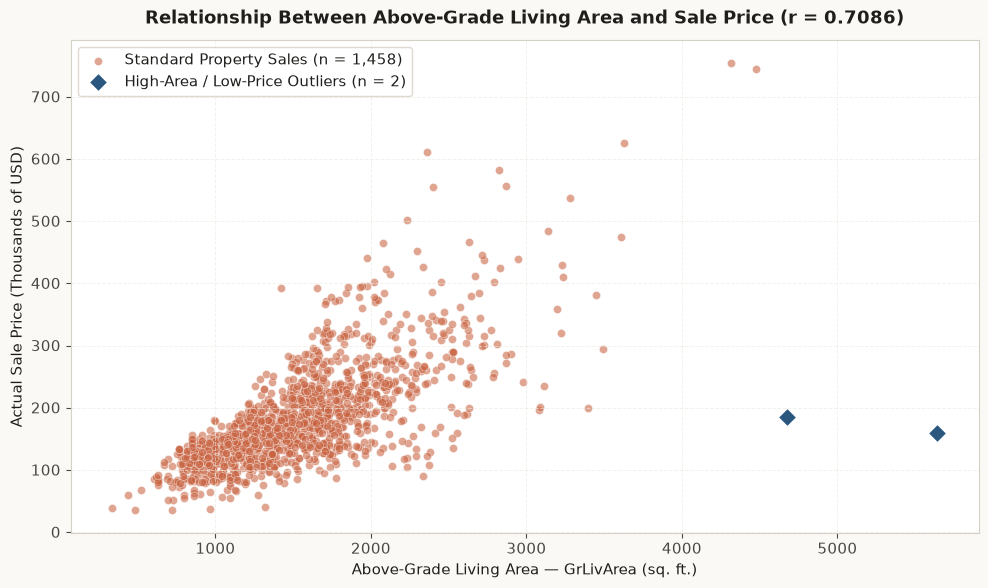

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

normal_mask = ~((df_clean["GrLivArea"] > 4000) & (df_clean["SalePrice"] < 300000))
ax.scatter(
    df_clean.loc[normal_mask, "GrLivArea"],
    df_clean.loc[normal_mask, "SalePrice"] / 1000,
    alpha=0.58,
    s=34,
    color="#C96442",
    edgecolors="#FFFFFF",
    linewidth=0.4,
    label="Standard Property Sales (n = 1,458)"
)
ax.scatter(
    df_clean.loc[~normal_mask, "GrLivArea"],
    df_clean.loc[~normal_mask, "SalePrice"] / 1000,
    alpha=0.95,
    s=85,
    color="#1F4E78",
    marker="D",
    edgecolors="#FFFFFF",
    linewidth=0.8,
    label="High-Area / Low-Price Outliers (n = 2)"
)

corr_val = df_clean["GrLivArea"].corr(df_clean["SalePrice"])
ax.set_title(f"Relationship Between Above-Grade Living Area and Sale Price (r = {corr_val:.4f})", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Above-Grade Living Area — GrLivArea (sq. ft.)", fontsize=11)
ax.set_ylabel("Actual Sale Price (Thousands of USD)", fontsize=11)
ax.grid(True, alpha=0.6)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D6D1C7")

plt.tight_layout()
plt.show()

**Step 4 Observations:**  
1. **Positive Linear Relationship:** As `GrLivArea` increases from ~500 sq. ft. toward 3,500 sq. ft., `SalePrice` rises steadily along an upward linear band (Pearson $r = 0.7086$).  
2. **Increasing Variance (Heteroscedasticity) & Outliers:** For smaller homes (`< 1,500` sq. ft.), prices cluster relatively tightly (`\$80k–\$190k`), whereas larger homes (`> 2,200` sq. ft.) exhibit wider price spread depending on neighborhood and quality. Two distinct outliers (`GrLivArea > 4,500` sq. ft. sold under `\$200k` — known partial-sale / agricultural anomalies) pull against the main trend.  
3. **Correlation Does Not Prove Causation:** While living area strongly correlates with sale price, a visible scatter relationship alone **does not prove causation**—both living area and price are simultaneously influenced by neighborhood affluence, construction quality, lot size, and market conditions.

## Step 5: Split the Data into Training and Testing Sets

We divide the 1,460 observations into an **80% training set** and a **20% testing set** using `random_state=42` for reproducibility.  
* **Training Data:** Used exclusively by Linear Regression to estimate the slope and intercept parameters.  
* **Testing Data:** Held strictly unseen during training and used solely to evaluate generalization performance on out-of-sample homes.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Total observations:    {len(X)}")
print(f"Training observations: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Testing observations:  {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")
print(f"Train-Test Index Overlap: {len(set(X_train.index).intersection(set(X_test.index)))} rows")

split_summary = pd.DataFrame({
    "Train_Mean": [X_train["GrLivArea"].mean(), y_train.mean()],
    "Train_Std": [X_train["GrLivArea"].std(), y_train.std()],
    "Test_Mean": [X_test["GrLivArea"].mean(), y_test.mean()],
    "Test_Std": [X_test["GrLivArea"].std(), y_test.std()],
}, index=["GrLivArea (sq. ft.)", "SalePrice (USD)"]).round(2)
display(split_summary)

Total observations:    1460
Training observations: 1168 (80.0%)
Testing observations:  292 (20.0%)
Train-Test Index Overlap: 0 rows


,Train_Mean,Train_Std,Test_Mean,Test_Std
GrLivArea (sq. ft.),1527.40,524.43,1467.71,527.85
SalePrice (USD),181441.54,77263.58,178839.81,87730.75


**Step 5 Analysis:**  
The 80:20 split allocates **1,168 homes** to training and **292 homes** to testing with **zero index overlap**. Both splits share closely aligned means and standard deviations (`1,527.40` vs `1,467.71` sq. ft. and `\$181,441.54` vs `\$178,839.81` sale price), confirming a representative evaluation split.

## Step 6: Train Simple Linear Regression

We fit `sklearn.linear_model.LinearRegression` strictly on `(X_train, y_train)` to learn the optimal Ordinary Least Squares (OLS) intercept $\beta_0$ and slope coefficient $\beta_1$.

Learned Intercept (beta_0): $24,899.75
Learned Slope (beta_1):     $102.49 per sq. ft.

Mathematical Equation:
  SalePrice_hat = 24,899.75 + 102.49 * GrLivArea

Word Equation:
  Predicted Sale Price (USD) = $24,899.75 + ($102.49 per sq. ft. x Above-Grade Living Area)


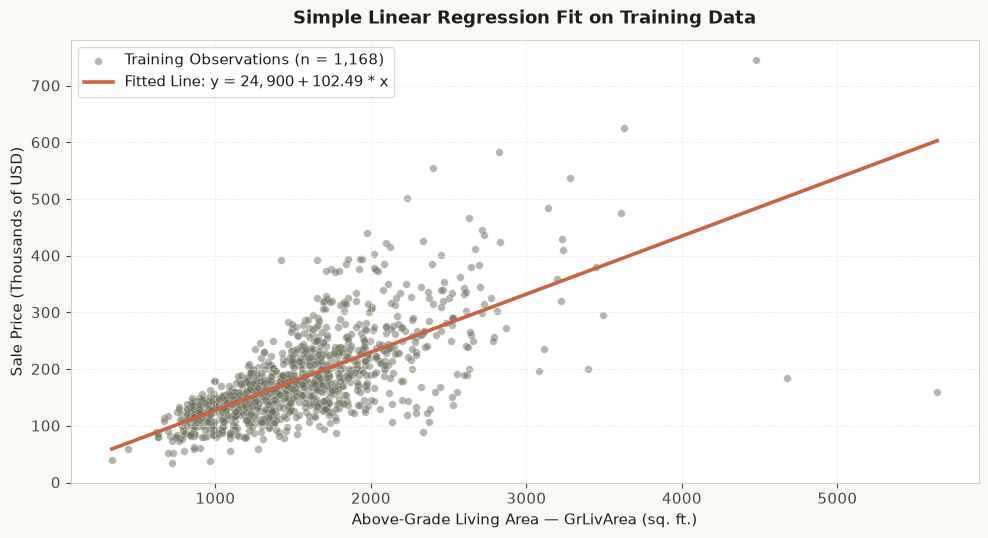

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = float(model.intercept_)
slope = float(model.coef_[0])

print(f"Learned Intercept (beta_0): ${intercept:,.2f}")
print(f"Learned Slope (beta_1):     ${slope:,.2f} per sq. ft.")
print("\nMathematical Equation:")
print(f"  SalePrice_hat = {intercept:,.2f} + {slope:,.2f} * GrLivArea")
print("\nWord Equation:")
print(f"  Predicted Sale Price (USD) = ${intercept:,.2f} + (${slope:,.2f} per sq. ft. x Above-Grade Living Area)")

# Plot regression line on training data
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(
    X_train["GrLivArea"], y_train / 1000,
    alpha=0.5, s=30, color="#6B705C", edgecolors="#FFFFFF", linewidth=0.3,
    label="Training Observations (n = 1,168)"
)
x_line = np.linspace(X_train["GrLivArea"].min(), X_train["GrLivArea"].max(), 200).reshape(-1, 1)
y_line = model.predict(pd.DataFrame(x_line, columns=["GrLivArea"]))
ax.plot(
    x_line, y_line / 1000,
    color="#C96442", linewidth=2.6,
    label=f"Fitted Line: y = ${intercept:,.0f} + ${slope:,.2f} * x"
)
ax.set_title("Simple Linear Regression Fit on Training Data", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Above-Grade Living Area — GrLivArea (sq. ft.)", fontsize=11)
ax.set_ylabel("Sale Price (Thousands of USD)", fontsize=11)
ax.grid(True, alpha=0.6)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D6D1C7")
plt.tight_layout()
plt.show()

**Step 6 Interpretation (Slope & Intercept):**  
* **Model Equation:** $\widehat{\text{SalePrice}} = 24{,}899.75 + 102.49 \times \text{GrLivArea}$  
* **Meaning of the Slope (`$102.49 / sq. ft.`):** Holding everything else outside the model unmodeled, each additional **1 square foot** of above-grade living area corresponds to an average increase of **\$102.49** in predicted sale price (about **\$10,249** per extra 100 sq. ft.).  
* **Meaning of the Intercept (`$24,899.75`):** Mathematically, this is the predicted price when `GrLivArea = 0` sq. ft. Because a zero-square-foot home does not exist in reality (minimum observed living area is `334` sq. ft.), the intercept serves as the linear baseline anchor rather than a standalone land price.

## Step 7: Generate Test Predictions

We apply the trained model exclusively to the **unseen test set** (`X_test`, 292 properties) and inspect side-by-side actual vs. predicted values. Training predictions are never reported as test results.

In [9]:
y_pred = model.predict(X_test)

test_results = pd.DataFrame({
    "Id": df_clean.loc[X_test.index, "Id"].values,
    "Neighborhood": df_clean.loc[X_test.index, "Neighborhood"].values,
    "OverallQual": df_clean.loc[X_test.index, "OverallQual"].values,
    "GrLivArea": X_test["GrLivArea"].values,
    "Actual_Price": y_test.values,
    "Predicted_Price": np.round(y_pred, 2),
})
test_results["Error"] = np.round(test_results["Actual_Price"] - test_results["Predicted_Price"], 2)
test_results["Abs_Error"] = np.abs(test_results["Error"]).round(2)
test_results["Pct_Error"] = np.round(test_results["Abs_Error"] / test_results["Actual_Price"] * 100, 2)

print("--- Sample of 12 Unseen Test Records: Actual vs. Predicted ---")
display(test_results.head(12))

print("\n--- Top 3 Closest Test Predictions ---")
display(test_results.sort_values("Abs_Error").head(3))

print("\n--- Top 3 Largest Error Test Predictions ---")
display(test_results.sort_values("Abs_Error", ascending=False).head(3))

--- Sample of 12 Unseen Test Records: Actual vs. Predicted ---


,Id,Neighborhood,OverallQual,GrLivArea,Actual_Price,Predicted_Price,Error,Abs_Error,Pct_Error
0,893,Sawyer,6,1068,154500,134357.96,20142.04,20142.04,13.04
1,1106,NoRidge,8,2622,325000,293625.80,31374.20,31374.20,9.65
2,414,OldTown,5,1028,115000,130258.40,-15258.40,15258.40,13.27
3,523,BrkSide,6,1664,159000,195441.38,-36441.38,36441.38,22.92
4,1037,Timber,9,1620,315500,190931.86,124568.14,124568.14,39.48
5,615,MeadowV,4,630,75500,89467.79,-13967.79,13967.79,18.50
6,219,Crawfor,7,1954,311500,225163.17,86336.83,86336.83,27.72
7,1161,NPkVill,6,1456,146000,174123.67,-28123.67,28123.67,19.26
8,650,MeadowV,4,630,84500,89467.79,-4967.79,4967.79,5.88
9,888,Edwards,5,1393,135500,167666.87,-32166.87,32166.87,23.74



--- Top 3 Closest Test Predictions ---


,Id,Neighborhood,OverallQual,GrLivArea,Actual_Price,Predicted_Price,Error,Abs_Error,Pct_Error
207,980,Sawyer,5,1121,139000,139789.87,-789.87,789.87,0.57
217,947,NAmes,5,1144,143000,142147.12,852.88,852.88,0.60
259,1448,CollgCr,8,2090,240000,239101.67,898.33,898.33,0.37



--- Top 3 Largest Error Test Predictions ---


,Id,Neighborhood,OverallQual,GrLivArea,Actual_Price,Predicted_Price,Error,Abs_Error,Pct_Error
74,899,NridgHt,9,2364,611657,267183.65,344473.35,344473.35,56.32
139,692,NoRidge,10,4316,755000,467242.09,287757.91,287757.91,38.11
168,1047,StoneBr,9,2868,556581,318838.08,237742.92,237742.92,42.71


**Step 7 Comparison & Error Observations:**  
* **Closest Unseen Test Predictions:** Mid-market homes such as `Id = 980` (`1,121` sq. ft., actual `\$139,000` vs predicted `\$139,789.87`, error `0.57%`), `Id = 947` (`1,144` sq. ft., actual `\$143,000` vs predicted `\$142,147.12`, error `0.60%`), and `Id = 1448` (`2,090` sq. ft., actual `\$240,000` vs predicted `\$239,101.67`, error `0.37%`) are predicted within less than `\$900` of actual price.  
* **Largest Error Test Predictions:** The biggest misses occur on luxury custom homes—such as `Id = 899` (`NridgHt`, `OverallQual = 9`, `2,364` sq. ft., actual `\$611,657` vs predicted `\$267,183.65`), `Id = 692` (`NoRidge`, `OverallQual = 10`, `4,316` sq. ft., actual `\$755,000` vs predicted `\$467,242.09`), and `Id = 1047` (`StoneBr`, `OverallQual = 9`, `2,868` sq. ft., actual `\$556,581` vs predicted `\$318,838.08`)—because square footage alone misses luxury finishes, neighborhood prestige, and basement area.

## Step 8: Evaluate the Model

We compute **MAE**, **MSE**, **RMSE**, and **$R^2$** strictly on the 292 test predictions and compare against a naive mean-baseline predictor.

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Mean-only baseline (always predicting training mean)
baseline_pred = np.full(shape=len(y_test), fill_value=y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

metrics_df = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Mean Squared Error (MSE)",
        "Root Mean Squared Error (RMSE)",
        "Coefficient of Determination (R²)"
    ],
    "Simple_Linear_Regression": [
        f"${mae:,.2f}",
        f"{mse:,.2f} USD²",
        f"${rmse:,.2f}",
        f"{r2:.4f} ({r2*100:.2f}%)"
    ],
    "Mean_Baseline": [
        f"${baseline_mae:,.2f}",
        f"{mean_squared_error(y_test, baseline_pred):,.2f} USD²",
        f"${baseline_rmse:,.2f}",
        f"{r2_score(y_test, baseline_pred):.4f}"
    ]
})
display(metrics_df)

mean_test_price = y_test.mean()
print(f"Test set average SalePrice: ${mean_test_price:,.2f}")
print(f"MAE as % of mean test price: {mae / mean_test_price * 100:.2f}%")
print(f"MAE improvement over naive mean baseline: {(baseline_mae - mae) / baseline_mae * 100:.2f}%")

,Metric,Simple_Linear_Regression,Mean_Baseline
0,Mean Absolute Error (MAE),"$38,341.20","$62,575.93"
1,Mean Squared Error (MSE),"3,418,946,311.18 USD²","7,677,095,207.78 USD²"
2,Root Mean Squared Error (RMSE),"$58,471.76","$87,619.03"
3,Coefficient of Determination (R²),0.5543 (55.43%),-0.0009


Test set average SalePrice: $178,839.81
MAE as % of mean test price: 21.44%
MAE improvement over naive mean baseline: 38.73%


**Step 8 Metric Definitions & Contextual Interpretation:**  
* **MAE (`$38,341.20`):** The **average absolute error** between predicted and actual prices across the 292 test homes. Relative to the test mean price (`\$178,839.81`), average prediction error is **21.44%**, reducing MAE by **38.73%** compared with always predicting the training mean (`\$62,575.93`).  
* **MSE (`3,418,946,311.18 USD²`):** The **average squared error** in squared dollars; squaring penalizes large luxury-home misses heavily.  
* **RMSE (`$58,471.76`):** The square root of MSE, returning the error metric to **target units (USD)**. Since `RMSE (\$58,471.76) > MAE (\$38,341.20)`, a small subset of extreme luxury homes contributes outsized squared errors.  
* **$R^2$ (`0.5543`):** Compares model squared error with a mean-based baseline (`R² = 0` matches predicting the test mean, `R² = 1` is exact prediction, and **`R²` can be negative on test data**—indeed, predicting the training mean gives `R² = -0.0009` on the test set). An $R^2$ of **0.5543** shows that living area alone explains **55.43%** of unseen sale-price variance, leaving **44.57%** driven by other property features.

## Step 9: Visualise Actual vs. Predicted Values

We compare actual test prices against model predictions relative to the 45° perfect-prediction line ($y = x$) and inspect the residual distribution.

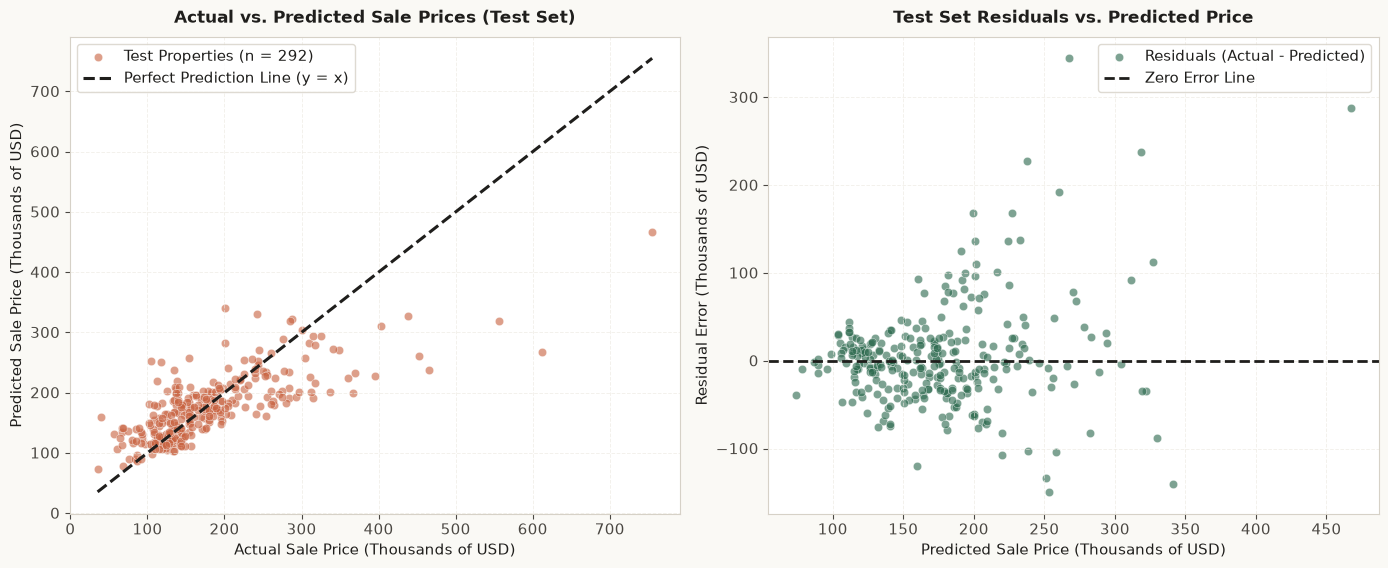

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

# Left: Actual vs Predicted
ax1 = axes[0]
ax1.scatter(
    y_test / 1000, y_pred / 1000,
    alpha=0.62, s=36, color="#C96442", edgecolors="#FFFFFF", linewidth=0.4,
    label="Test Properties (n = 292)"
)
min_val = min(y_test.min(), y_pred.min()) / 1000
max_val = max(y_test.max(), y_pred.max()) / 1000
ax1.plot(
    [min_val, max_val], [min_val, max_val],
    linestyle="--", linewidth=2.2, color="#1F1E1C",
    label="Perfect Prediction Line (y = x)"
)
ax1.set_title("Actual vs. Predicted Sale Prices (Test Set)", fontsize=12.5, fontweight="bold", pad=10)
ax1.set_xlabel("Actual Sale Price (Thousands of USD)", fontsize=10.5)
ax1.set_ylabel("Predicted Sale Price (Thousands of USD)", fontsize=10.5)
ax1.grid(True, alpha=0.6)
ax1.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D6D1C7")

# Right: Residual Plot
residuals = (y_test - y_pred) / 1000
ax2 = axes[1]
ax2.scatter(
    y_pred / 1000, residuals,
    alpha=0.62, s=36, color="#2D6A4F", edgecolors="#FFFFFF", linewidth=0.4,
    label="Residuals (Actual - Predicted)"
)
ax2.axhline(0, linestyle="--", linewidth=2.0, color="#1F1E1C", label="Zero Error Line")
ax2.set_title("Test Set Residuals vs. Predicted Price", fontsize=12.5, fontweight="bold", pad=10)
ax2.set_xlabel("Predicted Sale Price (Thousands of USD)", fontsize=10.5)
ax2.set_ylabel("Residual Error (Thousands of USD)", fontsize=10.5)
ax2.grid(True, alpha=0.6)
ax2.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D6D1C7")

plt.tight_layout()
plt.show()

**Step 9 Visual Interpretation:**  
1. **Proximity to the Reference Line:** For standard homes priced between **\$100k and \$240k**, test points cluster reasonably evenly around the dashed $y = x$ reference line.  
2. **Notable Large Errors:** Above **\$400k** actual price, points sit well below the $y = x$ diagonal (`Actual > Predicted`), showing systematic **under-prediction of premium homes** (such as `Id = 899`, `Id = 692`, and `Id = 1047`).  
3. **Residual Fanning:** The residual plot confirms wider error spread at higher predicted prices, indicating that single-feature regression lacks key predictors needed for luxury properties.

## Step 10: Predict a New Example and Conclude

We select a reasonable new property input comfortably inside the observed training range (`334 – 5,642` sq. ft.)—specifically **`GrLivArea = 1,800` sq. ft.**—and compute its predicted price in USD. For completeness, we also briefly illustrate a multi-feature comparison to highlight why real-estate pricing depends on multiple factors.

In [12]:
new_examples = pd.DataFrame({"GrLivArea": [1200, 1800, 2500]})
new_preds = model.predict(new_examples)

for area_sqft, pred_usd in zip(new_examples["GrLivArea"], new_preds):
    marker = "  <-- Primary New Example" if area_sqft == 1800 else ""
    print(f"GrLivArea = {area_sqft:,} sq. ft.  -->  Predicted SalePrice = ${pred_usd:,.2f} USD{marker}")

# Verify 1800 sq ft sits within training range
print(f"\nTraining GrLivArea range: {int(X_train['GrLivArea'].min()):,} to {int(X_train['GrLivArea'].max()):,} sq. ft.")

# Educational reference: compare single-feature R2 vs multi-feature Linear Regression on identical split
multi_features = ["GrLivArea", "OverallQual", "TotalBsmtSF", "GarageCars", "FullBath", "YearBuilt"]
multi_model = LinearRegression().fit(df_clean.loc[X_train.index, multi_features], y_train)
multi_pred = multi_model.predict(df_clean.loc[X_test.index, multi_features])
print(f"\nEducational Context — Multi-Feature ({len(multi_features)} features) Test R²: {r2_score(y_test, multi_pred):.4f} | Test MAE: ${mean_absolute_error(y_test, multi_pred):,.2f}")

GrLivArea = 1,200 sq. ft.  -->  Predicted SalePrice = $147,886.50 USD
GrLivArea = 1,800 sq. ft.  -->  Predicted SalePrice = $209,379.87 USD  <-- Primary New Example
GrLivArea = 2,500 sq. ft.  -->  Predicted SalePrice = $281,122.15 USD

Training GrLivArea range: 334 to 5,642 sq. ft.

Educational Context — Multi-Feature (6 features) Test R²: 0.7944 | Test MAE: $25,319.86


---
## Final Summary & Conclusion

### Data Analysis Key Findings
* **Dataset & Preparation:** Using the open-source **Ames Housing Dataset** (`1,460` properties × `81` columns, OpenML ID `42165`), structural missing values across 19 columns were cleaned without dropping valid observations (`0` remaining nulls, `0` duplicates), and non-predictive identifiers (`Id`) were excluded.
* **Model & Equation:** An 80:20 split (`1,168` train / `292` test, `random_state=42`) trained a Simple Linear Regression model using `GrLivArea` to predict `SalePrice` in USD:
  $$\widehat{\text{SalePrice}} = 24{,}899.75 + 102.49 \times \text{GrLivArea}$$
* **Test Evaluation:** On the 292 unseen test homes, the model achieved **MAE = \$38,341.20**, **MSE = 3,418,946,311.18 USD²**, **RMSE = \$58,471.76**, and **$R^2$ = 0.5543**, reducing MAE by **38.73%** relative to the training-mean baseline (**MAE = \$62,575.93**, **$R^2$ = -0.0009**).
* **New Property Prediction:** A home with **`1,800` sq. ft.** of above-grade living area (within the training range of `334–5,642` sq. ft.) is predicted at **`$209,379.87` USD**.

### Limitations & Next Steps
* **Single-Feature Limitations:** Property prices depend on many interrelated factors—overall construction quality (`OverallQual`), neighborhood location, basement size, garage capacity, age (`YearBuilt`), and broader market conditions—which a one-variable linear model cannot capture (`44.57%` of variance remains unexplained, and high-end homes are under-predicted). Adding 5 structural features raises test $R^2$ from `0.5543` to `0.7944` and lowers MAE to `\$25,319.86`.
* **Next Steps:** Explore the interactive **Regression Studio, AI Analyst & Live Market Intelligence** web interface (`python run_app.py`) to test live predictions and inspect real-time market context.